
Initial observations:
- Age: the median is 47 years; the middle 50% of clients are between 32.5 and 59 years old.
- Tenure: the median is 11 years, suggesting an established client base.
- Accounts: the median is 2.
- Balance: the mean is approximately 147,445, the median is 63,333, and the maximum is 16.32 million. High balances pull the mean upward, but that does not automatically make them errors.

In [16]:
# Youngest clients
display(
    df_demo_clean.loc[
        df_demo_clean["clnt_age"] == df_demo_clean["clnt_age"].min()
    ]
)

# Oldest clients
display(
    df_demo_clean.loc[
        df_demo_clean["clnt_age"] == df_demo_clean["clnt_age"].max()
    ]
)

# Mean age, balance and tenure
display(
    df_demo_clean[
        ["clnt_age", "bal", "clnt_tenure_yr"]
    ].mean().rename("mean")
)

# Gender counts and percentages across all cleaned profiles
gender_counts = df_demo_clean["gendr"].value_counts(dropna=False)

gender_summary = gender_counts.to_frame(name="client_count")
gender_summary["percentage"] = (
    gender_counts / len(df_demo_clean) * 100
).round(2)

display(gender_summary)

# Compare M and F counts; show both in case of a tie
mf_counts = (
    df_demo_clean.loc[
        df_demo_clean["gendr"].isin(["M", "F"]), "gendr"
    ]
    .value_counts()
    .reindex(["M", "F"], fill_value=0)
)

display(mf_counts.rename("client_count"))

if mf_counts.sum() > 0:
    display(
        mf_counts[mf_counts == mf_counts.max()]
        .rename("largest_group_count")
    )

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
70216,5417612,4.0,59.0,13.5,U,2.0,24435.08,7.0,7.0


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
1851,9206649,6.0,78.0,96.0,U,2.0,94240.29,1.0,4.0
31168,2859040,24.0,288.0,96.0,M,2.0,36297.66,6.0,9.0


clnt_age              46.442240
bal               147445.240641
clnt_tenure_yr        12.052950
Name: mean, dtype: float64

,client_count,percentage
gendr,,
U,24122,34.17
M,23724,33.61
F,22746,32.22
X,3,0.00


gendr
M    23724
F    22746
Name: client_count, dtype: int64

gendr
M    23724
Name: largest_group_count, dtype: int64

In [17]:
# Client tenure = time with Vanguard, not the client's age
# Use total months for more precise comparisons
tenure_months = df_demo_clean["clnt_tenure_mnth"]

# Longest-standing clients
print("Longest tenure (years):", tenure_months.max() / 12)

display(
    df_demo_clean.loc[
        tenure_months == tenure_months.max(),
        ["client_id", "clnt_tenure_yr", "clnt_tenure_mnth"]
    ]
)

# Average client tenure
print("Average tenure (years):", round(tenure_months.mean() / 12, 2))

# Newest clients in this dataset: shortest recorded tenure
print("Shortest tenure (years):", tenure_months.min() / 12)

display(
    df_demo_clean.loc[
        tenure_months == tenure_months.min(),
        ["client_id", "clnt_tenure_yr", "clnt_tenure_mnth"]
    ]
)

# Exact joining dates are not available in these columns

Longest tenure (years): 62.416666666666664


,client_id,clnt_tenure_yr,clnt_tenure_mnth
64690,357409,62.0,749.0


Average tenure (years): 12.55
Shortest tenure (years): 2.75


,client_id,clnt_tenure_yr,clnt_tenure_mnth
851,1954630,2.0,33.0
2009,4738135,2.0,33.0
19406,9169459,2.0,33.0
19624,2881524,2.0,33.0
24707,4929178,2.0,33.0
30784,6403610,2.0,33.0
38377,7943030,2.0,33.0
39265,4293151,2.0,33.0
41350,7260973,2.0,33.0
44088,7520125,2.0,33.0


In [18]:
datasets = {
    "Demographics": df_final_demo,
    "Experiment": df_final_experiment_clients,
    "Web events": df_final_web_data
}

for name, data in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", data.shape)
    print("Unique clients:", data["client_id"].nunique())
    print("Exact duplicate rows:", data.duplicated().sum())

    display(pd.DataFrame({
        "data_type": data.dtypes,
        "missing_count": data.isna().sum(),
        "missing_percentage": data.isna().mean().mul(100).round(2)
    }))

display(
    df_final_experiment_clients["Variation"]
    .value_counts(dropna=False)
)

display(
    df_final_web_data["process_step"]
    .value_counts(dropna=False)
)


--- Demographics ---
Shape: (70609, 9)
Unique clients: 70609
Exact duplicate rows: 0


,data_type,missing_count,missing_percentage
client_id,int64,0,0.00
clnt_tenure_yr,float64,14,0.02
clnt_tenure_mnth,float64,14,0.02
clnt_age,float64,15,0.02
gendr,str,14,0.02
num_accts,float64,14,0.02
bal,float64,14,0.02
calls_6_mnth,float64,14,0.02
logons_6_mnth,float64,14,0.02



--- Experiment ---
Shape: (70609, 2)
Unique clients: 70609
Exact duplicate rows: 0


,data_type,missing_count,missing_percentage
client_id,int64,0,0.00
Variation,str,20109,28.48



--- Web events ---
Shape: (755405, 5)
Unique clients: 120157
Exact duplicate rows: 10764


,data_type,missing_count,missing_percentage
client_id,int64,0,0.0
visitor_id,str,0,0.0
visit_id,str,0,0.0
process_step,str,0,0.0
date_time,str,0,0.0


Variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64

process_step
start      243945
step_1     163193
step_2     133062
step_3     112242
confirm    102963
Name: count, dtype: int64

In [22]:
df_web_clean = df_final_web_data.copy()

In [23]:
online_client_ids = df_web_clean["client_id"].dropna().unique()

df_online_clients = df_demo_clean.loc[
    df_demo_clean["client_id"].isin(online_client_ids)
].copy()

assert not df_online_clients.empty, "No matching online clients found."

print("Clients with usable profiles:", len(df_demo_clean))
print("Online clients with usable profiles:", len(df_online_clients))

print(
    "Web clients without a usable profile:",
    len(set(online_client_ids) - set(df_demo_clean["client_id"]))
)

Clients with usable profiles: 70595
Online clients with usable profiles: 70595
Web clients without a usable profile: 49562


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_online_clients["age_group"] = pd.cut(
    df_online_clients["clnt_age"],
    bins=[0, 18, 35, 50, 65, float("inf")],
    labels=["Under 18", "18–34", "35–49", "50–64", "65+"],
    right=False
)

df_online_clients["tenure_group"] = pd.cut(
    df_online_clients["clnt_tenure_mnth"] / 12,
    bins=[0, 5, 10, 20, float("inf")],
    labels=["Under 5 years", "5–9 years", "10–19 years", "20+ years"],
    right=False
)

def frequency_table(series):
    counts = series.value_counts(dropna=False)

    return pd.DataFrame({
        "client_count": counts,
        "percentage": counts / len(series) * 100
    }).round(2)

age_table = frequency_table(df_online_clients["age_group"])
tenure_table = frequency_table(df_online_clients["tenure_group"])
gender_table = frequency_table(df_online_clients["gendr"])

display(age_table)
display(tenure_table)
display(gender_table)

display(
    df_online_clients[
        ["clnt_age", "clnt_tenure_yr", "num_accts", "bal"]
    ].describe().T
)

,client_count,percentage
age_group,,
50–64,22499,31.87
18–34,20130,28.51
35–49,18346,25.99
65+,9245,13.10
Under 18,374,0.53
NaN,1,0.00


,client_count,percentage
tenure_group,,
10–19 years,27586,39.08
5–9 years,26404,37.40
20+ years,11388,16.13
Under 5 years,5217,7.39


,client_count,percentage
gendr,,
U,24122,34.17
M,23724,33.61
F,22746,32.22
X,3,0.00


,count,mean,std,min,25%,50%,75%,max
clnt_age,70594.0,46.442240,15.591273,13.50,32.500,47.0,59.000,96.00
clnt_tenure_yr,70595.0,12.052950,6.871819,2.00,6.000,11.0,16.000,62.00
num_accts,70595.0,2.255528,0.534997,1.00,2.000,2.0,2.000,8.00
bal,70595.0,147445.240641,301508.706531,13789.42,37346.835,63332.9,137544.905,16320040.15


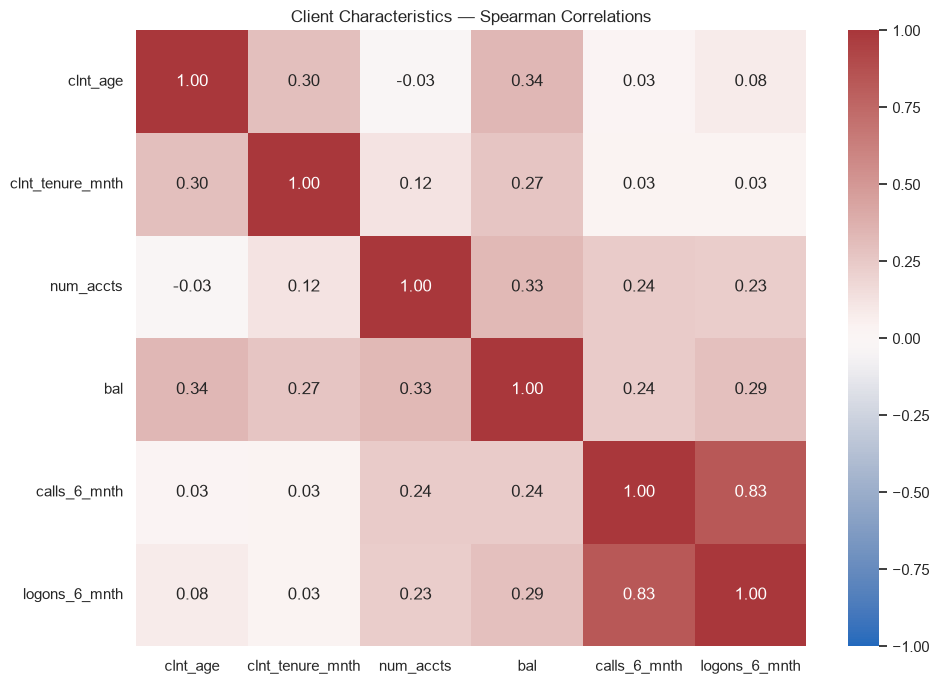

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_columns = [
    "clnt_age",
    "clnt_tenure_mnth",
    "num_accts",
    "bal",
    "calls_6_mnth",
    "logons_6_mnth"
]

correlation_matrix = (
    df_online_clients[correlation_columns]
    .corr(method="spearman")
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Client Characteristics — Spearman Correlations")
plt.tight_layout()
plt.show()

In [26]:
# Use the same complete observations for both methods
data = df_online_clients[["clnt_age", "bal"]].dropna()

pearson_r = data["clnt_age"].corr(data["bal"], method="pearson")
spearman_r = data["clnt_age"].corr(data["bal"], method="spearman")

print("Number of clients:", len(data))
print(f"Pearson correlation: {pearson_r:.3f}")
print(f"Spearman correlation: {spearman_r:.3f}")

Number of clients: 70594
Pearson correlation: 0.210
Spearman correlation: 0.343


In [27]:
# Include only clients coded F or M with a known balance
gender_balance = df_online_clients.loc[
    df_online_clients["gendr"].isin(["F", "M"]),
    ["gendr", "bal"]
].dropna().copy()

gender_balance["gender_code"] = (
    gender_balance["gendr"].map({"F": 0, "M": 1})
)

correlation = gender_balance["gender_code"].corr(
    gender_balance["bal"],
    method="pearson"
)

print(f"Point-biserial correlation: {correlation:.3f}")

# Compare group sizes, means and medians
display(
    gender_balance.groupby("gendr")["bal"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Point-biserial correlation: 0.110


,count,mean,median
gendr,,,
F,22746,135561.33,69028.80
M,23724,212299.87,85759.67


In [1]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/data-bootcamp-v4/lessons/main/5_6_eda_inf_stats_tableau/project/files_for_project/"

df_final_demo = pd.read_csv(base_url + "df_final_demo.txt")

df_final_experiment_clients = pd.read_csv(
    base_url + "df_final_experiment_clients.txt"
)

df_web_pt_1 = pd.read_csv(base_url + "df_final_web_data_pt_1.txt")
df_web_pt_2 = pd.read_csv(base_url + "df_final_web_data_pt_2.txt")

In [2]:
df_final_web_data = pd.concat(
    [df_web_pt_1, df_web_pt_2],
    ignore_index=True
)

In [3]:
print("Client profiles:", df_final_demo.shape)
display(df_final_demo.head())

print("Web data:", df_final_web_data.shape)
display(df_final_web_data.head())

print("Experiment clients:", df_final_experiment_clients.shape)
display(df_final_experiment_clients.head())

Client profiles: (70609, 9)


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0


Web data: (755405, 5)


,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


Experiment clients: (70609, 2)


,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


In [4]:
print(df_final_demo.shape)
print(df_final_web_data.shape)
print(df_final_experiment_clients.shape)

(70609, 9)
(755405, 5)
(70609, 2)


In [5]:
df_final_web_data.head()

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


In [6]:
def initial_check(df, name="DataFrame"):
    print(f"--- {name} ---")
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    
    print("\nData types:")
    print(df.dtypes)
    
    print("\nMissing values:")
    print(df.isna().sum())
    
    print("\nDuplicated rows:")
    print(df.duplicated().sum())
    
    print("\nFirst rows:")
    display(df.head())

In [7]:
df_combined = pd.merge(
    df_final_demo,
    df_final_experiment_clients,
    on="client_id",
    how="inner"
)

In [8]:
(df_combined.isna().mean() * 100).sort_values(ascending=False)

Variation           28.479372
clnt_age             0.021244
num_accts            0.019828
clnt_tenure_yr       0.019828
gendr                0.019828
clnt_tenure_mnth     0.019828
calls_6_mnth         0.019828
bal                  0.019828
logons_6_mnth        0.019828
client_id            0.000000
dtype: float64

In [9]:
df_combined.isna().sum()

client_id               0
clnt_tenure_yr         14
clnt_tenure_mnth       14
clnt_age               15
gendr                  14
num_accts              14
bal                    14
calls_6_mnth           14
logons_6_mnth          14
Variation           20109
dtype: int64

In [10]:
initial_check(df_final_demo, "Client profiles")
initial_check(df_final_experiment_clients, "Experiment assignment")
initial_check(df_final_web_data, "Web events")

print(
    "Repeated client IDs in demographics:",
    df_final_demo["client_id"].duplicated().sum()
)

print(
    "Repeated client IDs in experiment assignment:",
    df_final_experiment_clients["client_id"].duplicated().sum()
)

display(
    df_final_experiment_clients["Variation"].value_counts(dropna=False)
)

--- Client profiles ---
Shape: (70609, 9)

Columns:
['client_id', 'clnt_tenure_yr', 'clnt_tenure_mnth', 'clnt_age', 'gendr', 'num_accts', 'bal', 'calls_6_mnth', 'logons_6_mnth']

Data types:
client_id             int64
clnt_tenure_yr      float64
clnt_tenure_mnth    float64
clnt_age            float64
gendr                   str
num_accts           float64
bal                 float64
calls_6_mnth        float64
logons_6_mnth       float64
dtype: object

Missing values:
client_id            0
clnt_tenure_yr      14
clnt_tenure_mnth    14
clnt_age            15
gendr               14
num_accts           14
bal                 14
calls_6_mnth        14
logons_6_mnth       14
dtype: int64

Duplicated rows:
0

First rows:


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0


--- Experiment assignment ---
Shape: (70609, 2)

Columns:
['client_id', 'Variation']

Data types:
client_id    int64
Variation      str
dtype: object

Missing values:
client_id        0
Variation    20109
dtype: int64

Duplicated rows:
0

First rows:


,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


--- Web events ---
Shape: (755405, 5)

Columns:
['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time']

Data types:
client_id       int64
visitor_id        str
visit_id          str
process_step      str
date_time         str
dtype: object

Missing values:
client_id       0
visitor_id      0
visit_id        0
process_step    0
date_time       0
dtype: int64

Duplicated rows:
10764

First rows:


,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


Repeated client IDs in demographics: 0
Repeated client IDs in experiment assignment: 0


Variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64

In [11]:
# Inspect clients with at least one missing value
display(
    df_final_demo.loc[df_final_demo.isna().any(axis=1)]
)

# Check numeric ranges and distributions
display(df_final_demo.describe().T)

# Inspect gender codes, including missing values
display(df_final_demo["gendr"].value_counts(dropna=False))

# Check whether each client appears only once
print(
    "Repeated client IDs:",
    df_final_demo["client_id"].duplicated().sum()
)


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
4164,7402828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8316,355337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8677,8412164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9583,4666211,8.0,106.0,NaN,F,2.0,42550.55,4.0,7.0
13444,2222915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18066,4876926,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25961,5277910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28432,7616759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35323,8191345,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43518,1227228,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max
client_id,70609.0,5.004992e+06,2.877278e+06,169.00,2519329.000,5016978.0,7483085.000,9999839.00
clnt_tenure_yr,70595.0,1.205295e+01,6.871819e+00,2.00,6.000,11.0,16.000,62.00
clnt_tenure_mnth,70595.0,1.506594e+02,8.208985e+01,33.00,82.000,136.0,192.000,749.00
clnt_age,70594.0,4.644224e+01,1.559127e+01,13.50,32.500,47.0,59.000,96.00
num_accts,70595.0,2.255528e+00,5.349969e-01,1.00,2.000,2.0,2.000,8.00
bal,70595.0,1.474452e+05,3.015087e+05,13789.42,37346.835,63332.9,137544.905,16320040.15
calls_6_mnth,70595.0,3.382478e+00,2.236580e+00,0.00,1.000,3.0,6.000,7.00
logons_6_mnth,70595.0,5.566740e+00,2.353286e+00,1.00,4.000,5.0,7.000,9.00


gendr
U      24122
M      23724
F      22746
NaN       14
X          3
Name: count, dtype: int64

Repeated client IDs: 0


In [13]:
# Identify profiles with no information other than client_id
profile_columns = df_final_demo.columns.drop("client_id")

empty_profiles = (
    df_final_demo[profile_columns].isna().all(axis=1)
)

# Preserve excluded profiles for reference
df_demo_empty_profiles = df_final_demo.loc[empty_profiles].copy()

# Create a separate demographic dataset
df_demo_clean = df_final_demo.loc[~empty_profiles].copy()

# Keep the remaining missing age unchanged
print("Excluded empty profiles:", len(df_demo_empty_profiles))
print("Remaining profiles:", len(df_demo_clean))

display(df_demo_clean.isna().sum())

Excluded empty profiles: 14
Remaining profiles: 70595


client_id           0
clnt_tenure_yr      0
clnt_tenure_mnth    0
clnt_age            1
gendr               0
num_accts           0
bal                 0
calls_6_mnth        0
logons_6_mnth       0
dtype: int64

In [14]:
# Demographics: numeric ranges, gender codes and repeated IDs
display(df_demo_clean.describe().T)
display(df_demo_clean["gendr"].value_counts(dropna=False))

print(
    "Repeated demographic client IDs:",
    df_final_demo["client_id"].duplicated().sum()
)

# Experiment: missing values, duplicate rows and group assignments
print("\nEXPERIMENT")
display(df_final_experiment_clients.isna().sum())

print(
    "Duplicate rows:",
    df_final_experiment_clients.duplicated().sum()
)

print(
    "Repeated client IDs:",
    df_final_experiment_clients["client_id"].duplicated().sum()
)

display(
    df_final_experiment_clients["Variation"].value_counts(dropna=False)
)

# Web events: types, missing values, exact duplicates and process steps
print("\nWEB EVENTS")
display(df_final_web_data.dtypes)
display(df_final_web_data.isna().sum())

print(
    "Exact duplicate rows:",
    df_final_web_data.duplicated().sum()
)

display(
    df_final_web_data["process_step"].value_counts(dropna=False)
)

# Inspect timestamp conversion without changing the original column
parsed_dates = pd.to_datetime(
    df_final_web_data["date_time"],
    errors="coerce"
)

print(
    "Non-missing timestamps that could not be parsed:",
    (
        df_final_web_data["date_time"].notna()
        & parsed_dates.isna()
    ).sum()
)

print("First timestamp:", parsed_dates.min())
print("Last timestamp:", parsed_dates.max())

,count,mean,std,min,25%,50%,75%,max
client_id,70595.0,5.005021e+06,2.877269e+06,169.00,2519604.500,5016969.0,7483063.500,9999839.00
clnt_tenure_yr,70595.0,1.205295e+01,6.871819e+00,2.00,6.000,11.0,16.000,62.00
clnt_tenure_mnth,70595.0,1.506594e+02,8.208985e+01,33.00,82.000,136.0,192.000,749.00
clnt_age,70594.0,4.644224e+01,1.559127e+01,13.50,32.500,47.0,59.000,96.00
num_accts,70595.0,2.255528e+00,5.349969e-01,1.00,2.000,2.0,2.000,8.00
bal,70595.0,1.474452e+05,3.015087e+05,13789.42,37346.835,63332.9,137544.905,16320040.15
calls_6_mnth,70595.0,3.382478e+00,2.236580e+00,0.00,1.000,3.0,6.000,7.00
logons_6_mnth,70595.0,5.566740e+00,2.353286e+00,1.00,4.000,5.0,7.000,9.00


gendr
U    24122
M    23724
F    22746
X        3
Name: count, dtype: int64

Repeated demographic client IDs: 0

EXPERIMENT


client_id        0
Variation    20109
dtype: int64

Duplicate rows: 0
Repeated client IDs: 0


...

client_id       int64
visitor_id        str
visit_id          str
process_step      str
date_time         str
dtype: object

client_id       0
visitor_id      0
visit_id        0
process_step    0
date_time       0
dtype: int64

Exact duplicate rows: 10764


process_step
start      243945
step_1     163193
step_2     133062
step_3     112242
confirm    102963
Name: count, dtype: int64

Non-missing timestamps that could not be parsed: 0
First timestamp: 2017-03-15 00:03:03
Last timestamp: 2017-06-20 23:59:57


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_online_clients["age_group"] = pd.cut(
    df_online_clients["clnt_age"],
    bins=[0, 18, 35, 50, 65, float("inf")],
    labels=["Under 18", "18–34", "35–49", "50–64", "65+"],
    right=False
)

df_online_clients["tenure_group"] = pd.cut(
    df_online_clients["clnt_tenure_mnth"] / 12,
    bins=[0, 5, 10, 20, float("inf")],
    labels=["Under 5 years", "5–9 years", "10–19 years", "20+ years"],
    right=False
)

def frequency_table(series):
    counts = series.value_counts(dropna=False)

    return pd.DataFrame({
        "client_count": counts,
        "percentage": counts / len(series) * 100
    }).round(2)

age_table = frequency_table(df_online_clients["age_group"])
tenure_table = frequency_table(df_online_clients["tenure_group"])
gender_table = frequency_table(df_online_clients["gendr"])

display(age_table)
display(tenure_table)
display(gender_table)

display(
    df_online_clients[
        ["clnt_age", "clnt_tenure_yr", "num_accts", "bal"]
    ].describe().T
)

,client_count,percentage
age_group,,
50–64,22499,31.87
18–34,20130,28.51
35–49,18346,25.99
65+,9245,13.10
Under 18,374,0.53
NaN,1,0.00


,client_count,percentage
tenure_group,,
10–19 years,27586,39.08
5–9 years,26404,37.40
20+ years,11388,16.13
Under 5 years,5217,7.39


,client_count,percentage
gendr,,
U,24122,34.17
M,23724,33.61
F,22746,32.22
X,3,0.00


,count,mean,std,min,25%,50%,75%,max
clnt_age,70594.0,46.442240,15.591273,13.50,32.500,47.0,59.000,96.00
clnt_tenure_yr,70595.0,12.052950,6.871819,2.00,6.000,11.0,16.000,62.00
num_accts,70595.0,2.255528,0.534997,1.00,2.000,2.0,2.000,8.00
bal,70595.0,147445.240641,301508.706531,13789.42,37346.835,63332.9,137544.905,16320040.15


In [29]:
# Select online clients aged 50 or above
older_clients = df_online_clients.loc[
    df_online_clients["clnt_age"] >= 50
].copy()

# Express tenure in years using total months
tenure_years = older_clients["clnt_tenure_mnth"].dropna() / 12

print("Clients aged 50+:", len(older_clients))
print(f"Average tenure: {tenure_years.mean():.1f} years")
print(f"Median tenure: {tenure_years.median():.1f} years")
print(f"Shortest tenure: {tenure_years.min():.1f} years")
print(f"Longest tenure: {tenure_years.max():.1f} years")
print(
    f"Clients with 10+ years of tenure: "
    f"{tenure_years.ge(10).mean() * 100:.1f}%"
)

Clients aged 50+: 31744
Average tenure: 14.4 years
Median tenure: 13.5 years
Shortest tenure: 2.8 years
Longest tenure: 62.4 years
Clients with 10+ years of tenure: 64.4%


In [30]:
# Create descriptive age and tenure groups
client_profile = df_online_clients.copy()

client_profile["age_group"] = pd.cut(
    client_profile["clnt_age"],
    bins=[0, 18, 35, 50, 65, float("inf")],
    labels=["Under 18", "18–34", "35–49", "50–64", "65+"],
    right=False
)

client_profile["tenure_group"] = pd.cut(
    client_profile["clnt_tenure_mnth"] / 12,
    bins=[0, 5, 10, 20, float("inf")],
    labels=["Under 5 years", "5–9 years", "10–19 years", "20+ years"],
    right=False
)

# Include clients with known age and tenure
complete_profiles = client_profile.dropna(
    subset=["age_group", "tenure_group"]
)

# Find the most represented combinations
primary_segments = (
    complete_profiles
    .groupby(["age_group", "tenure_group"], observed=True)
    .size()
    .reset_index(name="client_count")
)

primary_segments["percentage"] = (
    primary_segments["client_count"] / len(complete_profiles) * 100
).round(2)

primary_segments = primary_segments.sort_values(
    "client_count",
    ascending=False
)

print("Clients included:", len(complete_profiles))
print("Clients excluded for missing age/tenure:",
      len(client_profile) - len(complete_profiles))

display(primary_segments.head(10))

Clients included: 70594
Clients excluded for missing age/tenure: 1


,age_group,tenure_group,client_count,percentage
5,18–34,5–9 years,10525,14.91
14,50–64,10–19 years,9070,12.85
10,35–49,10–19 years,8941,12.67
13,50–64,5–9 years,7306,10.35
9,35–49,5–9 years,6087,8.62
6,18–34,10–19 years,5848,8.28
15,50–64,20+ years,4781,6.77
18,65+,10–19 years,3684,5.22
19,65+,20+ years,2914,4.13
4,18–34,Under 5 years,2332,3.30


In [32]:
# Use online clients with a known balance
clients_with_balance = df_online_clients.dropna(
    subset=["bal"]
).copy()

# Define top clients using the 90th percentile
balance_threshold = clients_with_balance["bal"].quantile(0.90)

clients_with_balance["client_segment"] = "Other clients"

clients_with_balance.loc[
    clients_with_balance["bal"] >= balance_threshold,
    "client_segment"
] = "Top-balance clients"

top_clients = clients_with_balance.loc[
    clients_with_balance["client_segment"] == "Top-balance clients"
].copy()

print(f"Balance threshold: {balance_threshold:,.2f}")
print("Top-balance clients:", len(top_clients))
print(
    f"Percentage of clients: "
    f"{len(top_clients) / len(clients_with_balance) * 100:.2f}%"
)

display(
    top_clients[
        ["client_id", "clnt_age", "clnt_tenure_yr",
         "gendr", "num_accts", "bal"]
    ].sort_values("bal", ascending=False).head(20)
)

Balance threshold: 319,358.70
Top-balance clients: 7060
Percentage of clients: 10.00%


,client_id,clnt_age,clnt_tenure_yr,gendr,num_accts,bal
39367,9286288,62.5,21.0,M,3.0,16320040.15
63746,8339240,26.5,6.0,M,2.0,12838418.01
23849,7070097,53.0,11.0,M,2.0,8986419.77
13318,9440656,63.0,7.0,F,2.0,8292996.21
2171,2291985,41.0,7.0,M,2.0,8247729.97
20871,1678193,65.5,24.0,M,3.0,8137343.24
31811,6762377,41.5,16.0,F,3.0,8045102.60
14057,3519657,66.5,18.0,M,6.0,7741994.01
21184,987970,74.5,14.0,M,3.0,7339443.17
33222,857273,56.5,31.0,M,5.0,6716305.28


In [33]:
total_balance = clients_with_balance["bal"].sum()
top_balance = top_clients["bal"].sum()

top_balance_share = top_balance / total_balance * 100

print(f"Total balance held by top clients: {top_balance:,.2f}")
print(f"Share of all observed client balances: {top_balance_share:.2f}%")

Total balance held by top clients: 5,229,963,138.20
Share of all observed client balances: 50.25%


In [34]:
segment_summary = (
    clients_with_balance.groupby("client_segment")
    .agg(
        client_count=("client_id", "size"),
        median_balance=("bal", "median"),
        mean_balance=("bal", "mean"),
        median_age=("clnt_age", "median"),
        median_tenure_years=("clnt_tenure_yr", "median"),
        mean_accounts=("num_accts", "mean"),
        mean_calls=("calls_6_mnth", "mean"),
        mean_logins=("logons_6_mnth", "mean")
    )
)

display(segment_summary.round(2))

# Gender distribution within the top-balance segment
display(
    top_clients["gendr"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
    .rename("percentage")
)

,client_count,median_balance,mean_balance,median_age,median_tenure_years,mean_accounts,mean_calls,mean_logins
client_segment,,,,,,,,
Other clients,63535,56510.67,81513.08,45.0,10.0,2.21,3.26,5.44
Top-balance clients,7060,524860.00,740787.98,58.0,15.0,2.68,4.50,6.72


gendr
M    54.97
F    27.68
U    17.35
Name: percentage, dtype: float64

In [36]:
# Create a separate copy for balance segmentation
df_segmented = df_online_clients.copy()

df_segmented["balance_category"] = pd.cut(
    df_segmented["bal"],
    bins=[0, 50_000, 500_000, 5_000_000, float("inf")],
    labels=["Silver", "Gold", "Platinum", "Diamond"],
    right=False
)

# Summarize clients and balances by category
balance_summary = (
    df_segmented.groupby("balance_category", observed=False)
    .agg(
        client_count=("client_id", "size"),
        total_balance=("bal", "sum"),
        median_balance=("bal", "median")
    )
)

classified = df_segmented["balance_category"].notna()

balance_summary["client_percentage"] = (
    balance_summary["client_count"] / classified.sum() * 100
)

balance_summary["balance_percentage"] = (
    balance_summary["total_balance"]
    / df_segmented.loc[classified, "bal"].sum()
    * 100
)

display(balance_summary.round(2))

print("Unclassified clients (missing or negative balance):",
      (~classified).sum())

,client_count,total_balance,median_balance,client_percentage,balance_percentage
balance_category,,,,,
Silver,27650,9.355605e+08,33509.62,39.17,8.99
Gold,39133,5.530928e+09,102736.58,55.43,53.14
Platinum,3790,3.779912e+09,754062.65,5.37,36.31
Diamond,22,1.624963e+08,6597555.80,0.03,1.56


Unclassified clients (missing or negative balance): 0


In [37]:
category_profiles = (
    df_segmented.groupby("balance_category", observed=False)
    .agg(
        client_count=("client_id", "size"),
        mean_age=("clnt_age", "mean"),
        median_age=("clnt_age", "median"),
        median_tenure_years=("clnt_tenure_yr", "median"),
        mean_accounts=("num_accts", "mean"),
        mean_balance=("bal", "mean"),
        total_balance=("bal", "sum"),
        mean_calls=("calls_6_mnth", "mean"),
        mean_logins=("logons_6_mnth", "mean")
    )
)

display(category_profiles.round(2))

,client_count,mean_age,median_age,median_tenure_years,mean_accounts,mean_balance,total_balance,mean_calls,mean_logins
balance_category,,,,,,,,,
Silver,27650,41.43,39.50,8.0,2.09,33835.82,9.355605e+08,2.83,4.88
Gold,39133,48.92,50.00,12.0,2.32,141336.66,5.530928e+09,3.65,5.93
Platinum,3790,57.41,58.50,16.0,2.77,997338.35,3.779912e+09,4.66,6.87
Diamond,22,59.32,62.25,19.5,3.00,7386193.24,1.624963e+08,5.32,7.73


In [40]:
display(
    df_final_experiment_clients["Variation"]
    .fillna("Unassigned")
    .value_counts()
    .rename_axis("experiment_group")
    .reset_index(name="client_count")
)

,experiment_group,client_count
0,Test,26968
1,Control,23532
2,Unassigned,20109


In [38]:
# Select Diamond clients
diamond_clients = df_segmented.loc[
    df_segmented["balance_category"] == "Diamond"
]

# Count gender codes, including missing values
gender_counts = diamond_clients["gendr"].value_counts(dropna=False)

diamond_gender = gender_counts.to_frame(name="client_count")
diamond_gender["percentage"] = (
    gender_counts / len(diamond_clients) * 100
).round(2)

display(diamond_gender)

,client_count,percentage
gendr,,
M,19,86.36
F,3,13.64


In [39]:
# Count gender codes within every balance category
gender_by_category = (
    df_segmented.groupby(
        ["balance_category", "gendr"],
        observed=True,
        dropna=False
    )
    .size()
    .reset_index(name="client_count")
)

# Calculate percentages within each balance category
category_totals = (
    gender_by_category.groupby(
        "balance_category",
        observed=True,
        dropna=False
    )["client_count"]
    .transform("sum")
)

gender_by_category["percentage"] = (
    gender_by_category["client_count"] / category_totals * 100
).round(2)

display(gender_by_category)

,balance_category,gendr,client_count,percentage
0,Silver,F,8186,29.61
1,Silver,M,7151,25.86
2,Silver,U,12310,44.52
3,Silver,X,3,0.01
4,Gold,F,13601,34.76
5,Gold,M,14290,36.52
6,Gold,U,11242,28.73
7,Platinum,F,956,25.22
8,Platinum,M,2264,59.74
9,Platinum,U,570,15.04


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plot_df = df_segmented.copy()

assert plot_df["client_id"].is_unique, (
    "Each client must appear only once."
)

category_order = ["Silver", "Gold", "Platinum", "Diamond"]
category_colors = ["#A7ADB5", "#E7B745", "#7199B0", "#7868C4"]

def show_pie(values, title, colors=None):
    # Exclude empty slices
    values = values[values > 0]

    if values.empty:
        print(f"No data available: {title}")
        return

    fig, ax = plt.subplots(figsize=(8, 6))

    wedges, _ = ax.pie(
        values,
        startangle=90,
        colors=colors
    )

    percentages = values / values.sum() * 100

    ax.legend(
        wedges,
        [
            f"{label}: {percentage:.2f}%"
            for label, percentage in percentages.items()
        ],
        title="Share",
        loc="center left",
        bbox_to_anchor=(1, 0.5)
    )

    ax.set_title(title)
    ax.axis("equal")
    plt.tight_layout()
    plt.show()

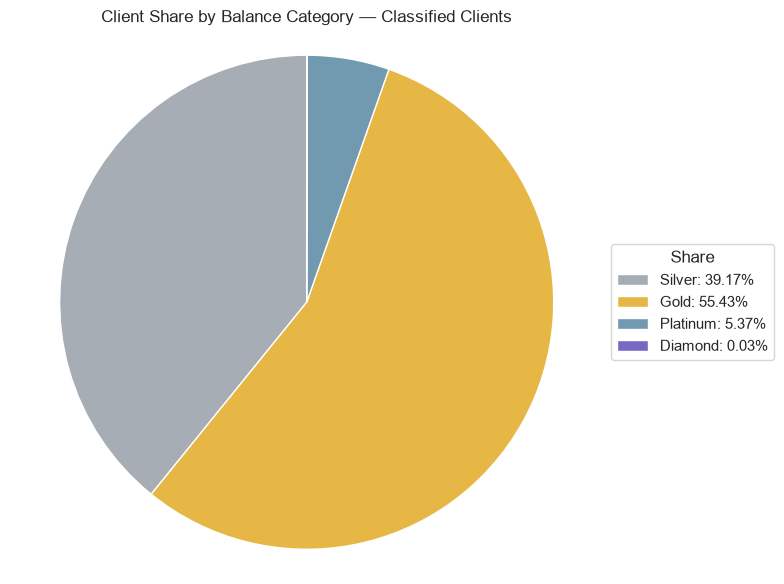

In [43]:
client_counts = (
    plot_df["balance_category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
)

show_pie(
    client_counts,
    "Client Share by Balance Category — Classified Clients",
    colors=category_colors
)

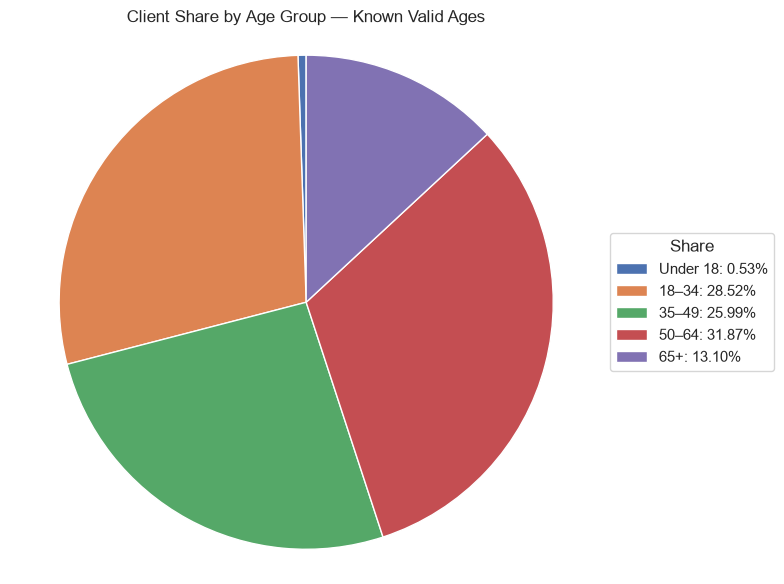

Clients excluded for missing or unclassified age: 1


In [44]:
age_order = ["Under 18", "18–34", "35–49", "50–64", "65+"]

plot_df["age_group"] = pd.cut(
    plot_df["clnt_age"],
    bins=[0, 18, 35, 50, 65, float("inf")],
    labels=age_order,
    right=False
)

age_counts = (
    plot_df["age_group"]
    .value_counts()
    .reindex(age_order, fill_value=0)
)

show_pie(
    age_counts,
    "Client Share by Age Group — Known Valid Ages"
)

print("Clients excluded for missing or unclassified age:",
      plot_df["age_group"].isna().sum())

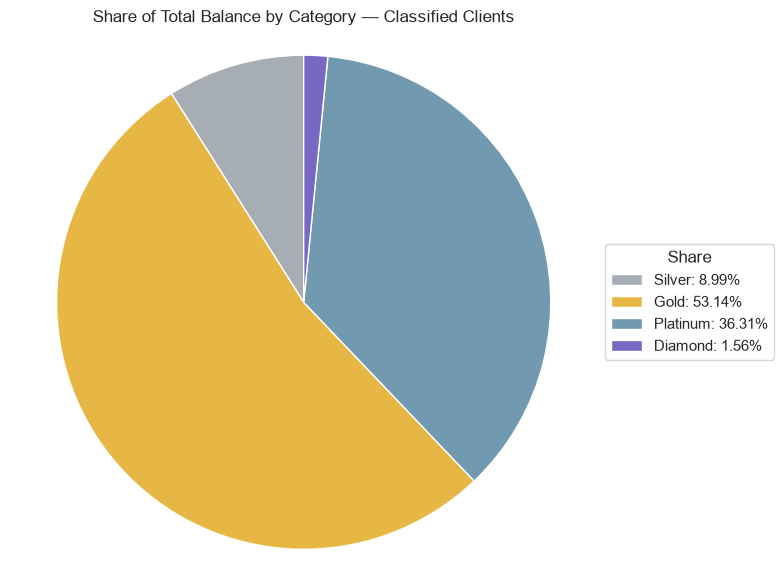

In [45]:
balance_totals = (
    plot_df.groupby("balance_category", observed=False)["bal"]
    .sum()
    .reindex(category_order, fill_value=0)
)

show_pie(
    balance_totals,
    "Share of Total Balance by Category — Classified Clients",
    colors=category_colors
)

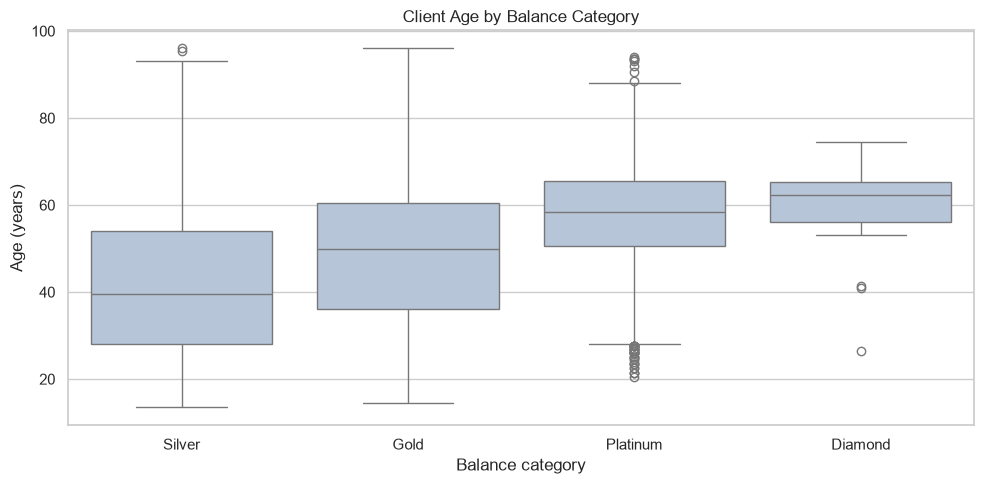

In [46]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=plot_df,
    x="balance_category",
    y="clnt_age",
    order=category_order,
    color="lightsteelblue"
)

plt.title("Client Age by Balance Category")
plt.xlabel("Balance category")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()

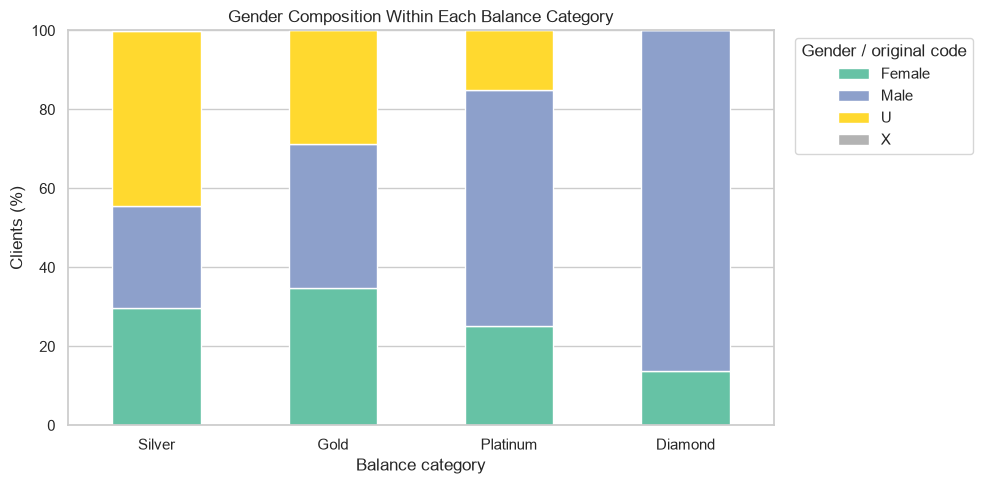

In [47]:
plot_df["gender_display"] = (
    plot_df["gendr"]
    .astype("string")
    .fillna("Missing")
    .replace({"M": "Male", "F": "Female"})
)

gender_counts = pd.crosstab(
    plot_df["balance_category"],
    plot_df["gender_display"]
).reindex(category_order, fill_value=0)

gender_percentages = (
    gender_counts
    .div(gender_counts.sum(axis=1).replace(0, float("nan")), axis=0)
    .mul(100)
)

ax = gender_percentages.plot.bar(
    stacked=True,
    figsize=(10, 5),
    colormap="Set2"
)

ax.set_title("Gender Composition Within Each Balance Category")
ax.set_xlabel("Balance category")
ax.set_ylabel("Clients (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.legend(title="Gender / original code", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

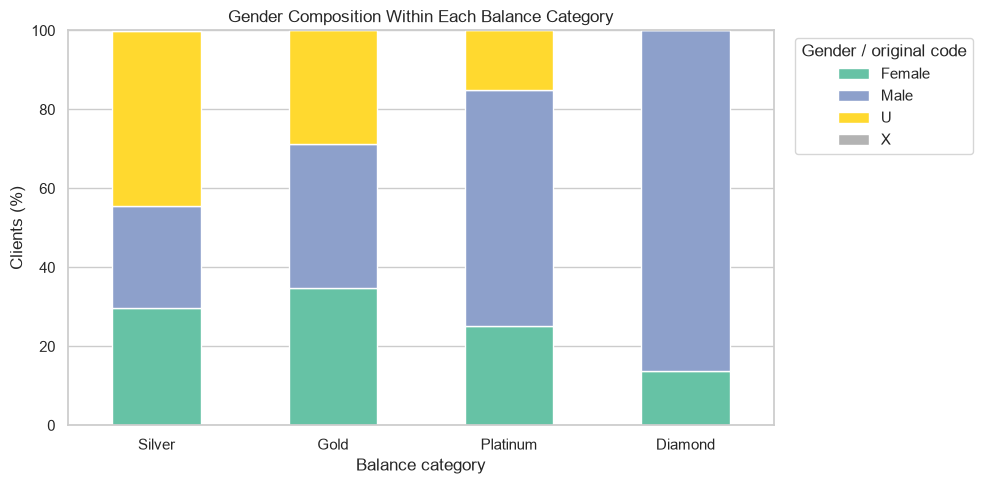

In [49]:
plot_df["gender_display"] = (
    plot_df["gendr"]
    .astype("string")
    .fillna("Missing")
    .replace({"M": "Male", "F": "Female"})
)

gender_counts = pd.crosstab(
    plot_df["balance_category"],
    plot_df["gender_display"]
).reindex(category_order, fill_value=0)

gender_percentages = (
    gender_counts
    .div(gender_counts.sum(axis=1).replace(0, float("nan")), axis=0)
    .mul(100)
)

ax = gender_percentages.plot.bar(
    stacked=True,
    figsize=(10, 5),
    colormap="Set2"
)

ax.set_title("Gender Composition Within Each Balance Category")
ax.set_xlabel("Balance category")
ax.set_ylabel("Clients (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.legend(title="Gender / original code", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

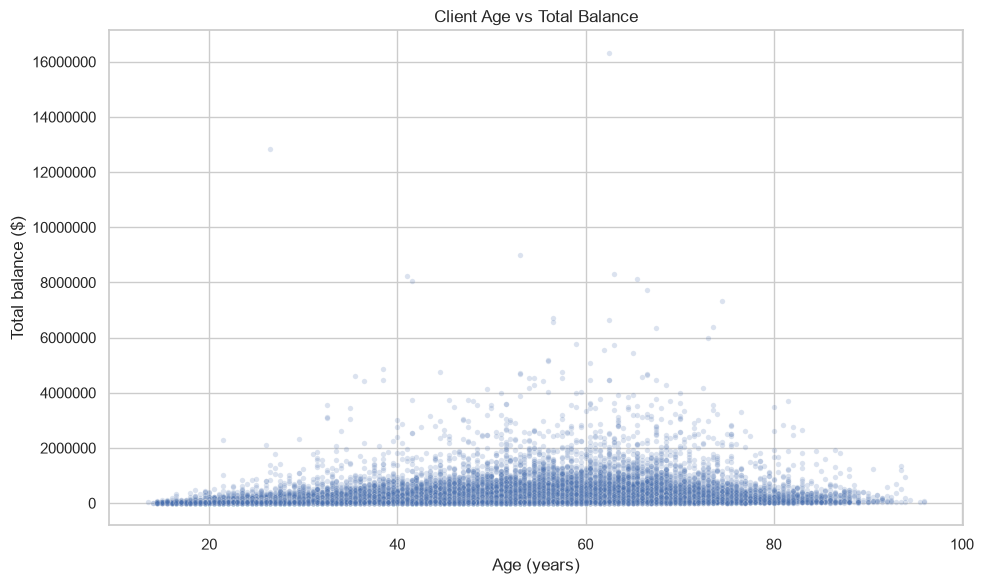

In [51]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_segmented,
    x="clnt_age",
    y="bal",
    alpha=0.2,
    s=15
)

plt.title("Client Age vs Total Balance")
plt.xlabel("Age (years)")
plt.ylabel("Total balance ($)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

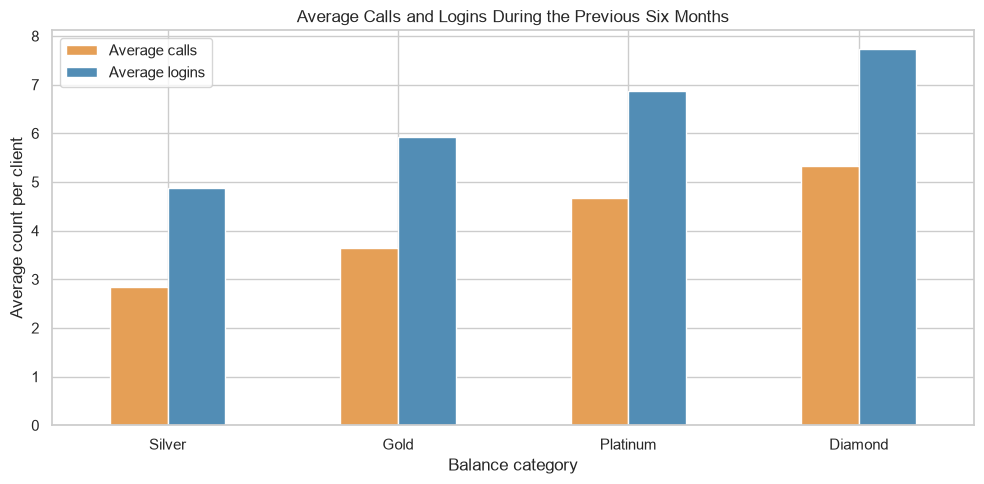

In [50]:
engagement = (
    plot_df.groupby("balance_category", observed=False)[
        ["calls_6_mnth", "logons_6_mnth"]
    ]
    .mean()
    .reindex(category_order)
    .rename(columns={
        "calls_6_mnth": "Average calls",
        "logons_6_mnth": "Average logins"
    })
)

ax = engagement.plot.bar(
    figsize=(10, 5),
    color=["#E59F56", "#528DB5"]
)

ax.set_title("Average Calls and Logins During the Previous Six Months")
ax.set_xlabel("Balance category")
ax.set_ylabel("Average count per client")
ax.tick_params(axis="x", rotation=0)

plt.legend(title="")
plt.tight_layout()
plt.show()

In [35]:
# Select online clients with a balance strictly above 5 million
clients_above_5m = df_online_clients.loc[
    df_online_clients["bal"] > 5_000_000
]

print("Clients with a balance above 5 million:", len(clients_above_5m))

display(
    clients_above_5m[
        ["client_id", "clnt_age", "clnt_tenure_yr", "bal"]
    ].sort_values("bal", ascending=False)
)

Clients with a balance above 5 million: 22


,client_id,clnt_age,clnt_tenure_yr,bal
39367,9286288,62.5,21.0,16320040.15
63746,8339240,26.5,6.0,12838418.01
23849,7070097,53.0,11.0,8986419.77
13318,9440656,63.0,7.0,8292996.21
2171,2291985,41.0,7.0,8247729.97
20871,1678193,65.5,24.0,8137343.24
31811,6762377,41.5,16.0,8045102.60
14057,3519657,66.5,18.0,7741994.01
21184,987970,74.5,14.0,7339443.17
33222,857273,56.5,31.0,6716305.28


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_online_clients["age_group"] = pd.cut(
    df_online_clients["clnt_age"],
    bins=[0, 18, 35, 50, 65, float("inf")],
    labels=["Under 18", "18–34", "35–49", "50–64", "65+"],
    right=False
)

df_online_clients["tenure_group"] = pd.cut(
    df_online_clients["clnt_tenure_mnth"] / 12,
    bins=[0, 5, 10, 20, float("inf")],
    labels=["Under 5 years", "5–9 years", "10–19 years", "20+ years"],
    right=False
)

def frequency_table(series):
    counts = series.value_counts(dropna=False)

    return pd.DataFrame({
        "client_count": counts,
        "percentage": counts / len(series) * 100
    }).round(2)

age_table = frequency_table(df_online_clients["age_group"])
tenure_table = frequency_table(df_online_clients["tenure_group"])
gender_table = frequency_table(df_online_clients["gendr"])

display(age_table)
display(tenure_table)
display(gender_table)

display(
    df_online_clients[
        ["clnt_age", "clnt_tenure_yr", "num_accts", "bal"]
    ].describe().T
)